# 07 — Protected Attributes EDA

Thesis-critical exploratory audit of the protected attributes and their likely proxies in `application_train.csv` / `application_test.csv`.

## Purpose

This notebook answers fairness-prep questions before modeling and mitigation:

- How is `CODE_GENDER` distributed in train and test, and what are the `XNA` rows?
- How is age (`DAYS_BIRTH`) distributed, and how does the raw default rate change across 10-year age bands?
- How large are the gender × 10-year age-band intersectional cells, and what are their base rates?
- Which application columns may act as proxies for gender or age?
- What descriptive outcome gaps exist **before** any model is trained?

**Context:** [01_application_eda.ipynb](01_application_eda.ipynb) · [docs/EDA.md](../../docs/EDA.md) · [docs/decisions.md](../../docs/decisions.md)

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Mitigation (pre / in / post)
- Fairness metrics on out-of-fold predictions (demographic parity, equal opportunity, equalized odds, thresholds)

Protected attributes (`CODE_GENDER`, `DAYS_BIRTH`) are **included** as model features and are also kept raw for fairness grouping (see `docs/decisions.md`). Findings here describe the labeled data, not a trained scorer.

## 0. Load data and define audit columns

Load the application tables, set the protected / grouping / proxy constants, and run basic integrity checks. Age bands and the gender × age labels reuse the pipeline definition in `src/features/application.py`, so the notebook and the fairness artifacts use the same cells.

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

_cwd = Path.cwd()
if not (_cwd / "data" / "application_train.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "application_train.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from src.constants import (  # noqa: E402
    AGE_BAND_COL,
    AGE_BAND_EDGES,
    AGE_YEARS_COL,
    DAYS_PER_YEAR,
    INTERSECTION_COL,
    PROTECTED_ATTRIBUTES,
)
from src.features.application import assign_age_band  # noqa: E402

DATA_DIR = Path("data")
PRIMARY_KEY = "SK_ID_CURR"
PROXY_CATEGORICAL = [
    "NAME_EDUCATION_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "NAME_CONTRACT_TYPE",
    "FLAG_OWN_CAR",
    "REGION_RATING_CLIENT",
]
PROXY_NUMERIC = [
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",
    "OWN_CAR_AGE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
]


def load_application_tables(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    paths = {
        "train": data_dir / "application_train.csv",
        "test": data_dir / "application_test.csv",
    }
    missing = [name for name, p in paths.items() if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Missing files in {data_dir}: {missing}")
    return pd.read_csv(paths["train"]), pd.read_csv(paths["test"])


train, test = load_application_tables(DATA_DIR)

assert PRIMARY_KEY in train.columns and PRIMARY_KEY in test.columns
assert train[PRIMARY_KEY].is_unique and test[PRIMARY_KEY].is_unique
assert train[PRIMARY_KEY].notna().all() and test[PRIMARY_KEY].notna().all()
assert "TARGET" in train.columns and "TARGET" not in test.columns
assert set(PROTECTED_ATTRIBUTES).issubset(train.columns)
assert set(PROTECTED_ATTRIBUTES).issubset(test.columns)

print(f"Protected attributes: {PROTECTED_ATTRIBUTES}")
print(f"Age band edges (years, left-closed): {AGE_BAND_EDGES}")
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} cols")
print(f"test:  {test.shape[0]:,} rows x {test.shape[1]} cols")

Protected attributes: ['CODE_GENDER', 'DAYS_BIRTH']
Age band edges (years, left-closed): [20, 30, 40, 50, 60, 70]
train: 307,511 rows x 122 cols
test:  48,744 rows x 121 cols


## 1. Gender distribution and `XNA`

Compare `CODE_GENDER` in train vs test, inspect the `XNA` rows, and compute raw default rates by gender. The `XNA` rows are excluded before training and evaluation; this section documents why.

CODE_GENDER counts, train vs test (incl. XNA):


,count_train,count_test,pct_train,pct_test
CODE_GENDER,,,,
F,202448,32678,65.834,67.04
M,105059,16066,34.164,32.96
XNA,4,0,0.001,0.00


XNA rows in train:


,SK_ID_CURR,CODE_GENDER,TARGET,DAYS_BIRTH,age_years
35657,141289,XNA,0,-20232,55.4
38566,144669,XNA,0,-13717,37.6
83382,196708,XNA,0,-10647,29.1
189640,319880,XNA,0,-9649,26.4


Train rows after excluding XNA: 307,507
Default rate by gender (train, XNA excluded):


,count,pct,default_rate,defaults,default_rate_pct
CODE_GENDER,,,,,
F,202448,65.8352,0.0700,14170,6.9993
M,105059,34.1648,0.1014,10655,10.1419


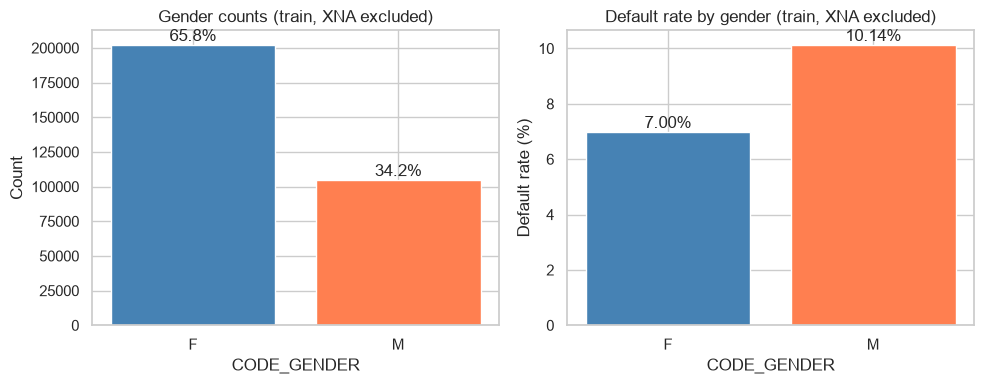

In [2]:
def group_profile(df: pd.DataFrame, col: str, with_target: bool = True) -> pd.DataFrame:
    counts = df[col].value_counts(dropna=False)
    out = pd.DataFrame({"count": counts, "pct": 100 * counts / len(df)})
    if with_target and "TARGET" in df.columns:
        rates = df.groupby(col, dropna=False, observed=True)["TARGET"].agg(
            default_rate="mean", defaults="sum"
        )
        out = out.join(rates)
        out["default_rate_pct"] = 100 * out["default_rate"]
    return out.sort_values("count", ascending=False)


gender_compare = (
    train["CODE_GENDER"].value_counts().rename("count_train").to_frame()
    .join(test["CODE_GENDER"].value_counts().rename("count_test"), how="outer")
    .fillna(0)
    .astype(int)
)
gender_compare["pct_train"] = 100 * gender_compare["count_train"] / len(train)
gender_compare["pct_test"] = 100 * gender_compare["count_test"] / len(test)
print("CODE_GENDER counts, train vs test (incl. XNA):")
display(gender_compare.round(3))

xna_rows = train.loc[train["CODE_GENDER"] == "XNA", [PRIMARY_KEY, "CODE_GENDER", "TARGET", "DAYS_BIRTH"]].assign(
    age_years=lambda d: (-d["DAYS_BIRTH"] / DAYS_PER_YEAR).round(1)
)
print("XNA rows in train:")
display(xna_rows)

train_no_xna = train[train["CODE_GENDER"] != "XNA"].copy()
test_no_xna = test[test["CODE_GENDER"] != "XNA"].copy()
gender_rates = group_profile(train_no_xna, "CODE_GENDER")
print(f"Train rows after excluding XNA: {len(train_no_xna):,}")
print("Default rate by gender (train, XNA excluded):")
display(gender_rates.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ["steelblue", "coral"]
axes[0].bar(gender_rates.index.astype(str), gender_rates["count"], color=colors)
axes[0].set_title("Gender counts (train, XNA excluded)")
axes[0].set_xlabel("CODE_GENDER")
axes[0].set_ylabel("Count")
for i, (_, row) in enumerate(gender_rates.iterrows()):
    axes[0].text(i, row["count"], f"{row['pct']:.1f}%", ha="center", va="bottom")
axes[1].bar(gender_rates.index.astype(str), gender_rates["default_rate_pct"], color=colors)
axes[1].set_title("Default rate by gender (train, XNA excluded)")
axes[1].set_xlabel("CODE_GENDER")
axes[1].set_ylabel("Default rate (%)")
for i, (_, row) in enumerate(gender_rates.iterrows()):
    axes[1].text(i, row["default_rate_pct"], f"{row['default_rate_pct']:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

gender_gap = gender_rates["default_rate"].max() - gender_rates["default_rate"].min()

**Interpretation:** Women are about 66% of train and 67% of test. The raw default rate is 7.00% for women and 10.14% for men, a gap of 3.14 pp. `XNA` appears in 4 train rows (0.001%) and in no test row; all 4 have `TARGET = 0`. With no positives, TPR and FNR are undefined for this group, and every other rate would rest on 4 people. The column description does not define `XNA`, so the rows are not reassigned to F or M either. The pipeline excludes them before training and evaluation (an exclusion forced by the data; see `docs/decisions.md`), leaving 307,507 train rows. This is an outcome gap in the labeled data, not a model fairness metric.

## 2. Age distribution

Check `DAYS_BIRTH` for missing values and sentinels, convert it to age in years (`−DAYS_BIRTH / 365.25`), and profile the raw default rate across the 10-year bands [20, 30), …, [60, 70).

DAYS_BIRTH integrity and age range (XNA excluded):


,train,test
missing_DAYS_BIRTH,0.00,0.00
positive_DAYS_BIRTH,0.00,0.00
min_DAYS_BIRTH,-25229.00,-25195.00
max_DAYS_BIRTH,-7489.00,-7338.00
min_age_years,20.50,20.09
max_age_years,69.07,68.98
median_age_years,43.12,43.22


Median age by gender (train):


,count,mean,std,min,25%,50%,75%,max
CODE_GENDER,,,,,,,,
F,202448.0,45.18,12.04,20.50,35.33,44.83,55.43,69.07
M,105059.0,41.45,11.38,21.02,32.03,40.26,50.04,68.98


Default rate by 10-year age band (train):


,count,pct,default_rate,defaults,default_rate_pct
AGE_BAND,,,,,
20-29,45184,14.6936,0.1144,5171,11.4443
30-39,82330,26.7734,0.0959,7897,9.5919
40-49,76599,24.9097,0.0764,5853,7.6411
50-59,68093,22.1436,0.0612,4168,6.1210
60-69,35301,11.4797,0.0492,1736,4.9177


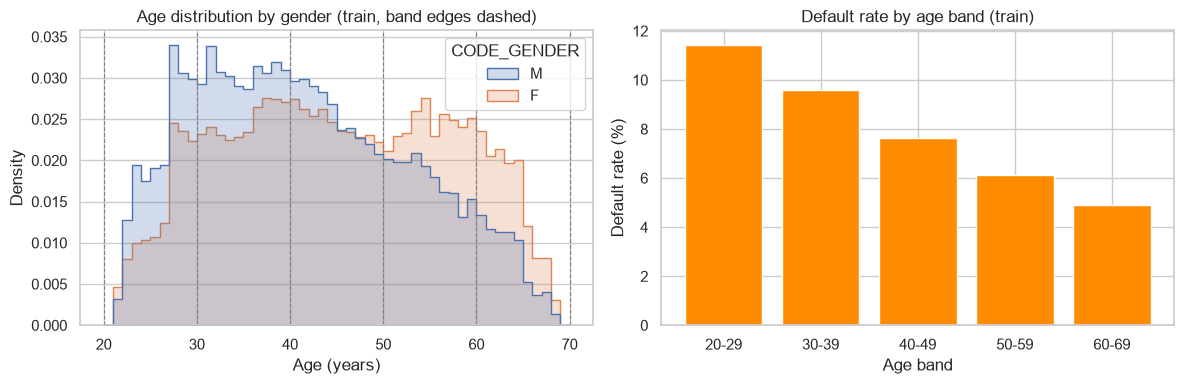

In [3]:
for name, df in [("train", train_no_xna), ("test", test_no_xna)]:
    df[AGE_YEARS_COL] = -df["DAYS_BIRTH"] / DAYS_PER_YEAR
    df[AGE_BAND_COL] = assign_age_band(df["DAYS_BIRTH"])
    df[INTERSECTION_COL] = df["CODE_GENDER"].astype(str) + " | " + df[AGE_BAND_COL]

age_checks = pd.DataFrame(
    {
        split: {
            "missing_DAYS_BIRTH": int(df["DAYS_BIRTH"].isna().sum()),
            "positive_DAYS_BIRTH": int((df["DAYS_BIRTH"] >= 0).sum()),
            "min_DAYS_BIRTH": int(df["DAYS_BIRTH"].min()),
            "max_DAYS_BIRTH": int(df["DAYS_BIRTH"].max()),
            "min_age_years": round(df[AGE_YEARS_COL].min(), 2),
            "max_age_years": round(df[AGE_YEARS_COL].max(), 2),
            "median_age_years": round(df[AGE_YEARS_COL].median(), 2),
        }
        for split, df in [("train", train_no_xna), ("test", test_no_xna)]
    }
)
print("DAYS_BIRTH integrity and age range (XNA excluded):")
display(age_checks)

print("Median age by gender (train):")
display(train_no_xna.groupby("CODE_GENDER")[AGE_YEARS_COL].describe().round(2))

band_rates = group_profile(train_no_xna, AGE_BAND_COL).sort_index()
print("Default rate by 10-year age band (train):")
display(band_rates.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(
    data=train_no_xna, x=AGE_YEARS_COL, hue="CODE_GENDER", bins=np.arange(20, 71, 1),
    element="step", stat="density", common_norm=False, ax=axes[0],
)
for edge in AGE_BAND_EDGES:
    axes[0].axvline(edge, color="grey", lw=0.8, ls="--")
axes[0].set_title("Age distribution by gender (train, band edges dashed)")
axes[0].set_xlabel("Age (years)")
axes[1].bar(band_rates.index.astype(str), band_rates["default_rate_pct"], color="darkorange")
axes[1].set_title("Default rate by age band (train)")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

age_gap = band_rates["default_rate"].max() - band_rates["default_rate"].min()

**Interpretation:** `DAYS_BIRTH` has no missing values, no non-negative values and no sentinel (unlike `DAYS_EMPLOYED`). Ages run from 20.5 to 69.1 in train and 20.1 to 69.0 in test, so every applicant falls in one of the five bands. Women are older on average (median 44.8 vs 40.3); the age histogram shows a larger female share above 50. The raw default rate falls steadily with age, from 11.44% in 20–29 to 4.92% in 60–69 (gap 6.53 pp), which is a larger gap than the gender gap.

## 3. Intersectionality: gender × 10-year age bands

Build the `GENDER_AGE` cells and report, for each cell, its size, positives, negatives, share, and base rate. No minimum cell size is applied (see `docs/decisions.md`); counts are reported for every cell.

Gender x age-band cells (train, XNA excluded): 10


n  positives  negatives  share_pct  base_rate_pct
CODE_GENDER AGE_BAND                                                       
F           20-29     25649       2725      22924       8.34          10.62
            30-39     50119       4365      45754      16.30           8.71
            40-49     49636       3313      46323      16.14           6.67
            50-59     49350       2517      46833      16.05           5.10
            60-69     27694       1250      26444       9.01           4.51
M           20-29     19535       2446      17089       6.35          12.52
            30-39     32211       3532      28679      10.47          10.97
            40-49     26963       2540      24423       8.77           9.42
            50-59     18743       1651      17092       6.10           8.81
            60-69      7607        486       7121       2.47           6.39

Smallest cell: M | 60-69 (n=7,607, positives=486, negatives=7,121)
Minimum over cells: n=7,607, positives=486, negatives=7,121


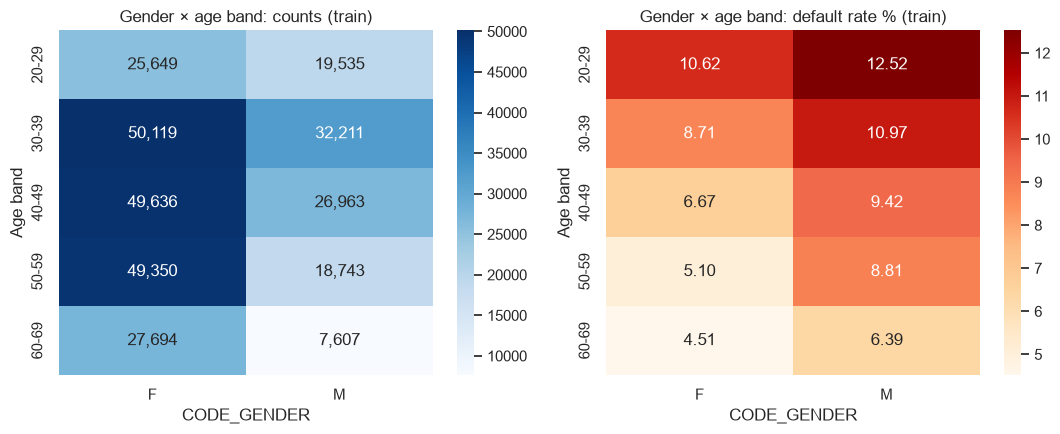

In [4]:
inter = (
    train_no_xna.groupby(["CODE_GENDER", AGE_BAND_COL], observed=True)["TARGET"]
    .agg(n="size", positives="sum", base_rate="mean")
    .assign(
        negatives=lambda d: d["n"] - d["positives"],
        share_pct=lambda d: 100 * d["n"] / d["n"].sum(),
        base_rate_pct=lambda d: 100 * d["base_rate"],
    )
)
print(f"Gender x age-band cells (train, XNA excluded): {len(inter)}")
display(inter[["n", "positives", "negatives", "share_pct", "base_rate_pct"]].round(2))

smallest = inter.sort_values("n").iloc[0]
print(
    "Smallest cell: "
    f"{' | '.join(inter.sort_values('n').index[0])} "
    f"(n={int(smallest['n']):,}, positives={int(smallest['positives']):,}, "
    f"negatives={int(smallest['negatives']):,})"
)
print(
    "Minimum over cells: "
    f"n={int(inter['n'].min()):,}, positives={int(inter['positives'].min()):,}, "
    f"negatives={int(inter['negatives'].min()):,}"
)

count_pivot = inter["n"].unstack("CODE_GENDER")
rate_pivot = inter["base_rate_pct"].unstack("CODE_GENDER")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(count_pivot, annot=True, fmt=",.0f", cmap="Blues", ax=axes[0])
axes[0].set_title("Gender × age band: counts (train)")
axes[0].set_ylabel("Age band")
sns.heatmap(rate_pivot, annot=True, fmt=".2f", cmap="OrRd", ax=axes[1])
axes[1].set_title("Gender × age band: default rate % (train)")
axes[1].set_ylabel("Age band")
plt.tight_layout()
plt.show()

inter_gap = inter["base_rate"].max() - inter["base_rate"].min()

**Interpretation:** The 10 cells range from 7,607 rows (`M | 60-69`, 486 positives, 7,121 negatives) to 50,119 rows (`F | 30-39`). Every cell has hundreds of positives and thousands of negatives, so no cell is sparse and no minimum-cell-size rule is needed. Within each age band men have a higher base rate than women, and within each gender the base rate falls with age. The extremes are `M | 20-29` (12.52%) and `F | 60-69` (4.51%), a spread of 8.01 pp, wider than either the gender gap or the age-band gap alone.

## 4. Raw disparity diagnostics and train/test representation

Summarize descriptive outcome gaps and compare group shares between train and test. These are **not** model fairness metrics: they describe `TARGET`, not predictions.

In [5]:
def representation_table(train_df: pd.DataFrame, test_df: pd.DataFrame, col: str) -> pd.DataFrame:
    tr = train_df[col].value_counts(normalize=True)
    te = test_df[col].value_counts(normalize=True)
    out = pd.DataFrame({"train_share": tr, "test_share": te}).fillna(0)
    out["abs_diff_pp"] = 100 * (out["train_share"] - out["test_share"]).abs()
    return out.sort_index()


diagnostics = pd.DataFrame(
    [
        {"metric": "overall_default_rate_pct", "value": 100 * train_no_xna["TARGET"].mean(),
         "note": "Train base rate after excluding XNA"},
        {"metric": "gender_default_gap_pp", "value": 100 * gender_gap,
         "note": "max−min default rate across F/M"},
        {"metric": "age_band_default_gap_pp", "value": 100 * age_gap,
         "note": "max−min default rate across 10-year age bands"},
        {"metric": "intersection_default_gap_pp", "value": 100 * inter_gap,
         "note": "max−min default rate across gender × age-band cells"},
        {"metric": "n_intersection_cells", "value": len(inter),
         "note": "Number of gender × age-band cells"},
    ]
)
print("Descriptive outcome gaps (train):")
display(diagnostics.round(3))

for col in ["CODE_GENDER", AGE_BAND_COL, INTERSECTION_COL]:
    print(f"Representation train vs test: {col}")
    display(representation_table(train_no_xna, test_no_xna, col).round(4))

Descriptive outcome gaps (train):


,metric,value,note
0,overall_default_rate_pct,8.073,Train base rate after excluding XNA
1,gender_default_gap_pp,3.143,max−min default rate across F/M
2,age_band_default_gap_pp,6.527,max−min default rate across 10-year age bands
3,intersection_default_gap_pp,8.008,max−min default rate across gender × age-band cells
4,n_intersection_cells,10.000,Number of gender × age-band cells


Representation train vs test: CODE_GENDER


,train_share,test_share,abs_diff_pp
CODE_GENDER,,,
F,0.6584,0.6704,1.2048
M,0.3416,0.3296,1.2048


Representation train vs test: AGE_BAND


,train_share,test_share,abs_diff_pp
AGE_BAND,,,
20-29,0.1469,0.1411,0.5791
30-39,0.2677,0.2690,0.1284
40-49,0.2491,0.2562,0.7078
50-59,0.2214,0.2170,0.4465
60-69,0.1148,0.1167,0.1894


Representation train vs test: GENDER_AGE


,train_share,test_share,abs_diff_pp
GENDER_AGE,,,
F | 20-29,0.0834,0.0751,0.8262
F | 30-39,0.1630,0.1695,0.6533
F | 40-49,0.1614,0.1718,1.0381
F | 50-59,0.1605,0.1598,0.0711
F | 60-69,0.0901,0.0942,0.4106
M | 20-29,0.0635,0.0660,0.2471
M | 30-39,0.1047,0.0995,0.5249
M | 40-49,0.0877,0.0844,0.3303
M | 50-59,0.0610,0.0572,0.3755


**Interpretation:** The base rate after excluding `XNA` is 8.07%. The descriptive gap grows from gender only (3.14 pp) to age band only (6.53 pp) to the gender × age cells (8.01 pp), which is why the fairness stage reports intersectional results alongside single-attribute ones. Train and test mixes are close: no gender, age-band or intersectional share differs by more than about 1.2 pp.

## 5. Proxy candidates

Measure how strongly selected application columns are associated with gender or age. This is an **audit list for later fairness work**, not a decision to exclude any feature. Association with gender uses Cramér's V (categoricals) and the gap in medians (numerics); association with age uses Spearman correlation (numerics) and the correlation ratio η (categoricals).

Categorical proxy candidates (train):


,n_levels,pct_missing,cramers_v_gender,eta_age
column,,,,
OCCUPATION_TYPE,18,31.345,0.508,0.452
FLAG_OWN_CAR,2,0.000,0.346,0.130
ORGANIZATION_TYPE,58,0.000,0.337,0.637
NAME_INCOME_TYPE,8,0.000,0.170,0.620
NAME_FAMILY_STATUS,6,0.000,0.168,0.311
NAME_HOUSING_TYPE,6,0.000,0.066,0.246
NAME_EDUCATION_TYPE,5,0.000,0.026,0.200
REGION_RATING_CLIENT,3,0.000,0.019,0.011
NAME_CONTRACT_TYPE,2,0.000,0.009,0.086


Numeric proxy candidates (train):


,pct_missing,spearman_age,median_F,median_M
column,,,,
EXT_SOURCE_1,56.381,0.600,0.558,0.381
CNT_CHILDREN,0.000,-0.367,0.000,0.000
DAYS_EMPLOYED,18.007,-0.307,-1762.000,-1476.000
DAYS_REGISTRATION,0.000,-0.295,-4651.000,-4240.000
CNT_FAM_MEMBERS,0.001,-0.273,2.000,2.000
DAYS_ID_PUBLISH,0.000,-0.264,-3260.000,-3244.000
EXT_SOURCE_3,19.826,0.205,0.541,0.526
EXT_SOURCE_2,0.215,0.102,0.568,0.562
AMT_INCOME_TOTAL,0.000,-0.084,135000.000,180000.000


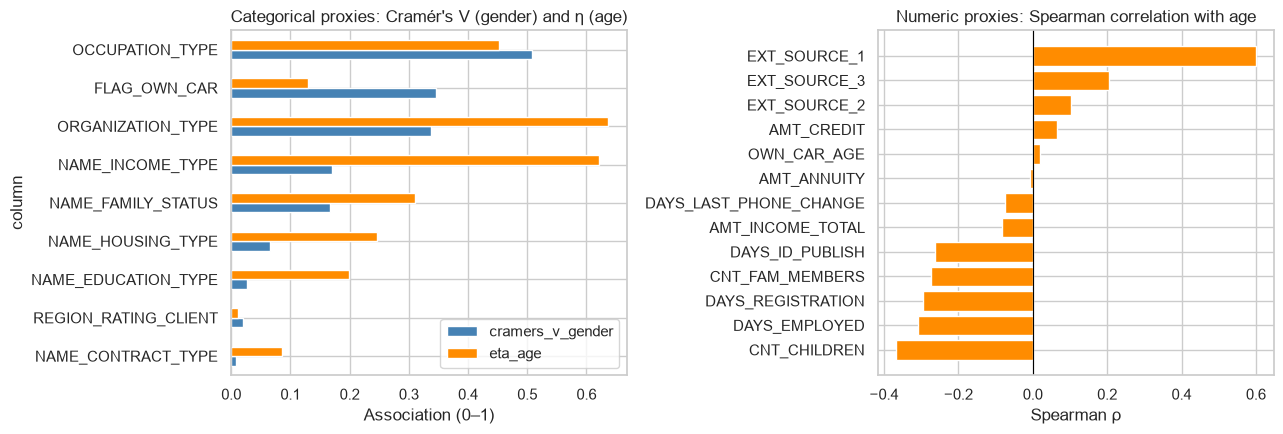

In [6]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    k = min(table.shape) - 1
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else np.nan


def correlation_ratio(categories: pd.Series, values: pd.Series) -> float:
    frame = pd.DataFrame({"cat": categories, "val": values}).dropna()
    grand_mean = frame["val"].mean()
    stats = frame.groupby("cat", observed=True)["val"].agg(["count", "mean"])
    between = (stats["count"] * (stats["mean"] - grand_mean) ** 2).sum()
    total = ((frame["val"] - grand_mean) ** 2).sum()
    return float(np.sqrt(between / total)) if total > 0 else np.nan


audit = train_no_xna.copy()
# DAYS_EMPLOYED sentinel 365243 -> NaN, as in the feature pipeline
audit.loc[audit["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan

categorical_assoc = pd.DataFrame(
    [
        {
            "column": col,
            "n_levels": audit[col].nunique(),
            "pct_missing": 100 * audit[col].isna().mean(),
            "cramers_v_gender": cramers_v(audit[col].fillna("__MISSING__"), audit["CODE_GENDER"]),
            "eta_age": correlation_ratio(audit[col].fillna("__MISSING__"), audit[AGE_YEARS_COL]),
        }
        for col in PROXY_CATEGORICAL
    ]
).set_index("column")

numeric_assoc = pd.DataFrame(
    [
        {
            "column": col,
            "pct_missing": 100 * audit[col].isna().mean(),
            "spearman_age": audit[[col, AGE_YEARS_COL]].corr(method="spearman").iloc[0, 1],
            "median_F": audit.loc[audit["CODE_GENDER"] == "F", col].median(),
            "median_M": audit.loc[audit["CODE_GENDER"] == "M", col].median(),
        }
        for col in PROXY_NUMERIC
    ]
).set_index("column")

print("Categorical proxy candidates (train):")
display(categorical_assoc.sort_values("cramers_v_gender", ascending=False).round(3))
print("Numeric proxy candidates (train):")
display(numeric_assoc.reindex(numeric_assoc["spearman_age"].abs().sort_values(ascending=False).index).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cat_plot = categorical_assoc.sort_values("cramers_v_gender")
cat_plot[["cramers_v_gender", "eta_age"]].plot.barh(ax=axes[0], color=["steelblue", "darkorange"])
axes[0].set_title("Categorical proxies: Cramér's V (gender) and η (age)")
axes[0].set_xlabel("Association (0–1)")
num_plot = numeric_assoc["spearman_age"].sort_values()
axes[1].barh(num_plot.index, num_plot.values, color="darkorange")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Numeric proxies: Spearman correlation with age")
axes[1].set_xlabel("Spearman ρ")
plt.tight_layout()
plt.show()

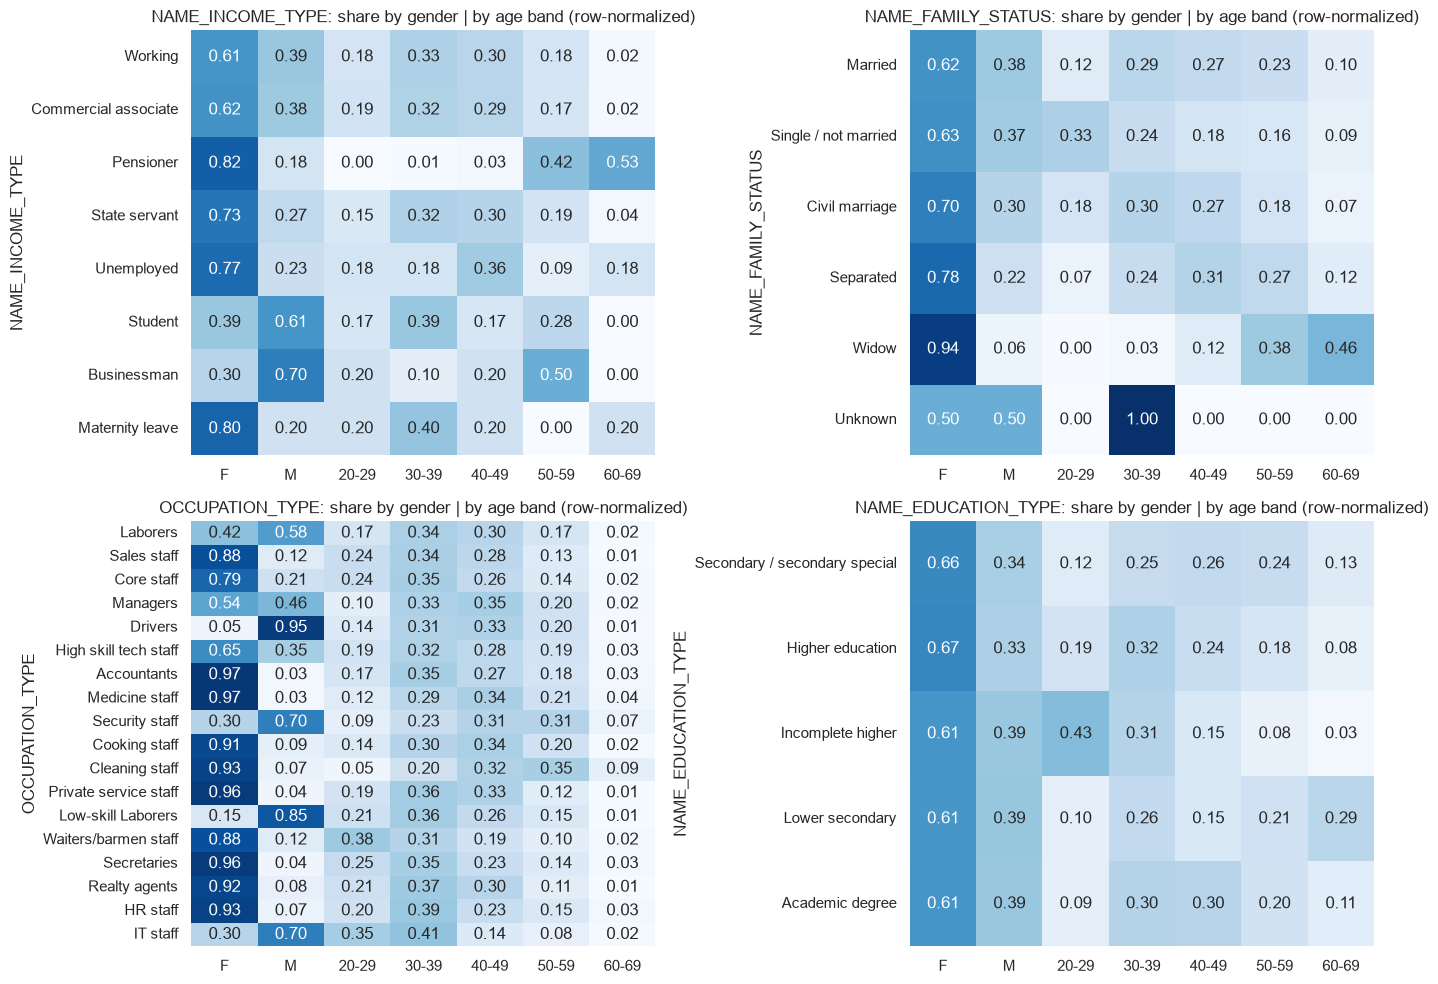

In [7]:
# Composition of the strongest categorical proxies (row-normalized)
focus_cats = ["NAME_INCOME_TYPE", "NAME_FAMILY_STATUS", "OCCUPATION_TYPE", "NAME_EDUCATION_TYPE"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.ravel(), focus_cats):
    order = audit[col].value_counts().index
    gender_share = pd.crosstab(audit[col], audit["CODE_GENDER"], normalize="index").reindex(order)
    band_share = pd.crosstab(audit[col], audit[AGE_BAND_COL], normalize="index").reindex(order)
    sns.heatmap(
        pd.concat([gender_share, band_share], axis=1), annot=True, fmt=".2f",
        cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False,
    )
    ax.set_title(f"{col}: share by gender | by age band (row-normalized)")
    ax.set_xlabel("")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

**Interpretation:**

- **Gender proxies.** `OCCUPATION_TYPE` is the strongest (Cramér's V 0.51): drivers, low-skill laborers, security and IT staff are mostly men, while accountants, medicine staff, secretaries and most service occupations are over 90% women. `FLAG_OWN_CAR` (0.35) and `ORGANIZATION_TYPE` (0.34) follow. Education is only weakly associated with gender (0.03).
- **Age proxies.** `ORGANIZATION_TYPE` (η 0.64) and `NAME_INCOME_TYPE` (η 0.62) are driven by pensioners: `Pensioner` applicants have a mean age of 59.7, and almost all of them have `ORGANIZATION_TYPE = XNA` and the `DAYS_EMPLOYED` sentinel. Among numerics, `EXT_SOURCE_1` has the strongest correlation with age (Spearman 0.60, but 56% missing), followed by `CNT_CHILDREN` (−0.37) and the tenure fields `DAYS_EMPLOYED`, `DAYS_REGISTRATION` and `DAYS_ID_PUBLISH` (−0.26 to −0.31; the `DAYS_*` values are negative, so a negative ρ means longer tenure for older applicants).
- **Both.** `OCCUPATION_TYPE`, `ORGANIZATION_TYPE` and `NAME_INCOME_TYPE` are associated with both gender and age, so they can carry gender × age information. `NAME_FAMILY_STATUS = Widow` is 94% women and concentrated above 50.

These associations are for monitoring in the fairness stage (Phase 1, Step 5), not automatic feature exclusions.

## Summary of findings

- **Protected attributes:** `CODE_GENDER` (F / M / XNA) and age from `DAYS_BIRTH`. Both are model features (gender one-hot, `DAYS_BIRTH` numeric) and are kept raw in `fairness_groups_*` with `AGE_BAND` and `GENDER_AGE` labels.
- **XNA:** 4 train rows (0.001%), 0 test rows, all `TARGET = 0`. Excluded before training and evaluation as an exclusion forced by the data: no group metric can be estimated, and the rows are not redistributed to F/M.
- **Gender:** about 66% F / 34% M in train. Raw default rate F 7.00%, M 10.14% (gap 3.14 pp).
- **Age:** no missing values or sentinel; ages 20.5–69.1 (train). Women are older (median 44.8 vs 40.3). Default rate falls from 11.44% (20–29) to 4.92% (60–69).
- **Intersectionality:** 10 gender × 10-year age-band cells. Smallest: `M | 60-69` (7,607 rows, 486 positives, 7,121 negatives), so no cell is sparse. Men have the higher base rate in every band; max−min across cells 8.01 pp (`M | 20-29` 12.52% vs `F | 60-69` 4.51%).
- **Train vs test:** gender, age-band and intersectional shares differ by at most about 1.2 pp.
- **Proxy candidates:** for gender `OCCUPATION_TYPE` (V 0.51), `FLAG_OWN_CAR`, `ORGANIZATION_TYPE`; for age `ORGANIZATION_TYPE` and `NAME_INCOME_TYPE` (pensioners), `EXT_SOURCE_1`, `CNT_CHILDREN` and the `DAYS_*` tenure fields. Monitor in the fairness stage; no exclusion decided.